# Unit 7 – Multi-layer perceptron with the sigmoid function
A single perceptron cannot learn XOR. Adding a hidden layer with a **sigmoid** activation, σ(z) = 1 / (1 + e^−z), lets the network bend its decision boundary. The network is implemented in NumPy (2 inputs → hidden layer → 1 output) and trained by back-propagation on a squared-error loss.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
np.random.seed(42)

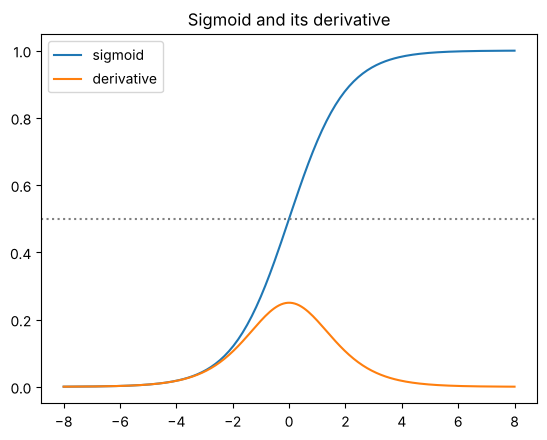

In [2]:
def sigmoid(z): return 1 / (1 + np.exp(-z))
def d_sigmoid(a): return a * (1 - a)          # derivative expressed through the activation a = sigmoid(z)

z = np.linspace(-8, 8, 200)
plt.plot(z, sigmoid(z), label='sigmoid'); plt.plot(z, d_sigmoid(sigmoid(z)), label="derivative")
plt.axhline(.5, c='grey', ls=':'); plt.legend(); plt.title('Sigmoid and its derivative'); plt.show()

    x1   x2  XOR target  network output  rounded
0  0.0  0.0         0.0           0.016        0
1  0.0  1.0         1.0           0.985        1
2  1.0  0.0         1.0           0.986        1
3  1.0  1.0         0.0           0.017        0


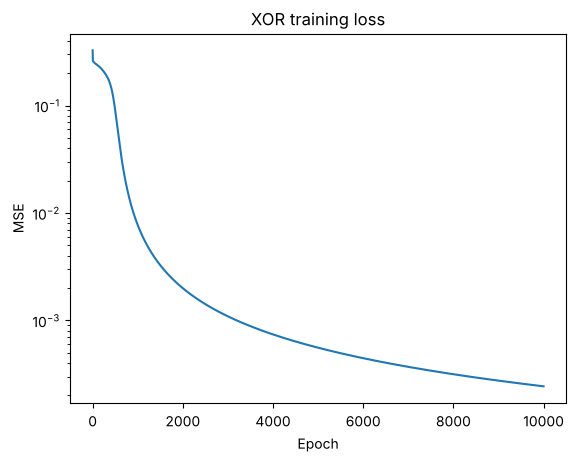

In [3]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)           # XOR

def train_mlp(hidden=4, lr=0.5, epochs=10000, seed=0):
    rng = np.random.RandomState(seed)
    W1 = rng.normal(0, 1, (2, hidden)); b1 = np.zeros((1, hidden))
    W2 = rng.normal(0, 1, (hidden, 1)); b2 = np.zeros((1, 1))
    losses = []
    for _ in range(epochs):
        h = sigmoid(X @ W1 + b1); out = sigmoid(h @ W2 + b2)            # forward pass
        losses.append(float(np.mean((y - out) ** 2)))
        d_out = (out - y) * d_sigmoid(out)                              # backward pass
        d_h = (d_out @ W2.T) * d_sigmoid(h)
        W2 -= lr * h.T @ d_out; b2 -= lr * d_out.sum(0, keepdims=True)
        W1 -= lr * X.T @ d_h;   b1 -= lr * d_h.sum(0, keepdims=True)
    return (W1, b1, W2, b2), losses

params, losses = train_mlp()
W1, b1, W2, b2 = params
pred = sigmoid(sigmoid(X @ W1 + b1) @ W2 + b2)
print(pd.DataFrame({'x1': X[:, 0], 'x2': X[:, 1], 'XOR target': y[:, 0], 'network output': pred[:, 0].round(3),
                    'rounded': (pred[:, 0] > .5).astype(int)}))
plt.plot(losses); plt.yscale('log'); plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.title('XOR training loss'); plt.show()

## Experiment – hidden units, learning rate, number of epochs

In [4]:
rows = []
for hidden in (1, 2, 4, 8):
    for lr in (0.05, 0.5, 2.0):
        _, l = train_mlp(hidden=hidden, lr=lr, epochs=5000)
        W = _; out = sigmoid(sigmoid(X @ W[0] + W[1]) @ W[2] + W[3])
        rows.append({'hidden_units': hidden, 'lr': lr, 'final_loss': round(l[-1], 4),
                     'XOR solved': bool(((out > .5).astype(int) == y).all())})
pd.DataFrame(rows)

,hidden_units,lr,final_loss,XOR solved
0,1,0.05,0.1844,False
1,1,0.50,0.1675,False
2,1,2.00,0.1668,False
3,2,0.05,0.1404,False
4,2,0.50,0.1258,False
5,2,2.00,0.1252,False
6,4,0.05,0.0899,True
7,4,0.50,0.0006,True
8,4,2.00,0.0001,True
9,8,0.05,0.0203,True


## Observations
* A network with 4 sigmoid hidden units solved XOR (outputs 0.016, 0.985, 0.986, 0.017 for the four cases).
* With 1 or 2 hidden units XOR was **not** solved in 5000 epochs (final loss 0.125–0.184); with 4 or 8 hidden units it was solved at every learning rate tested.
* A learning rate of 0.05 was too slow for 4 hidden units (loss 0.0899 after 5000 epochs) while 0.5 and 2.0 reached 0.0006 and 0.0001.